# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.datasets import make_moons
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from scipy.cluster.hierarchy import dendrogram, linkage

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [2]:
customer_data = pd.read_csv('shopping-data.csv')

In [3]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [4]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

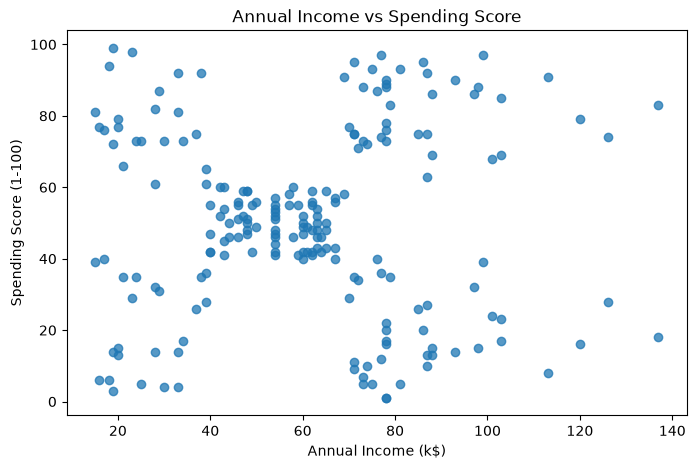

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'], alpha=0.75)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Annual Income vs Spending Score')
plt.show()

#### 3. Normalize the data

In [6]:
shopping_features = customer_data[['Annual Income (k$)', 'Spending Score (1-100)']]
shopping_scaler = StandardScaler()
X_shopping = shopping_scaler.fit_transform(shopping_features)
print('Scaled feature shape:', X_shopping.shape)

Scaled feature shape: (200, 2)


#### 4. Use Elbow method to decide number of clusters

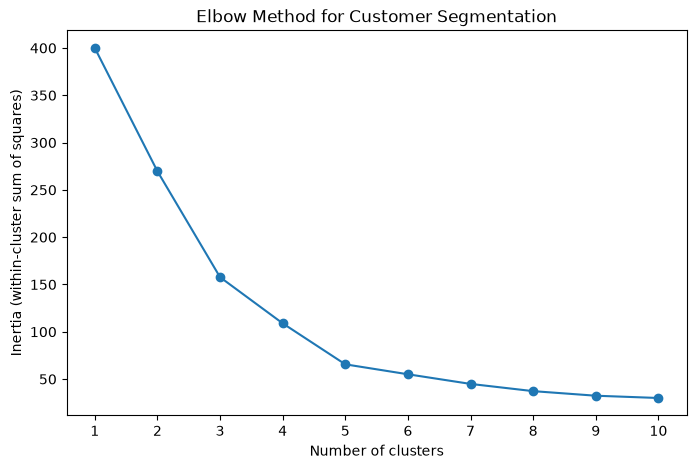

In [7]:
inertias = []
cluster_counts = range(1, 11)
for n_clusters in cluster_counts:
    model = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    model.fit(X_shopping)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(cluster_counts, inertias, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia (within-cluster sum of squares)')
plt.title('Elbow Method for Customer Segmentation')
plt.xticks(list(cluster_counts))
plt.show()

#### 5. Perform Clustering using KMeans

In [8]:
kmeans_shopping = KMeans(n_clusters=5, random_state=42, n_init=10)
shopping_kmeans_labels = kmeans_shopping.fit_predict(X_shopping)
print('KMeans cluster sizes:', pd.Series(shopping_kmeans_labels).value_counts().sort_index().to_dict())

KMeans cluster sizes: {0: 81, 1: 39, 2: 22, 3: 35, 4: 23}


#### 6. Plot scatter plot and color code in clustered groups

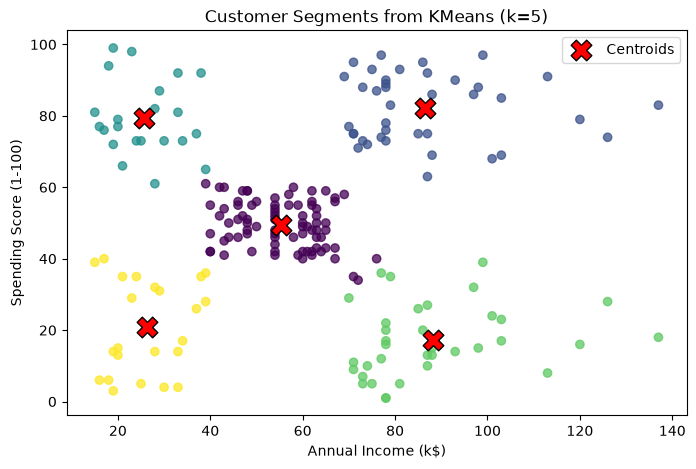

In [9]:
cluster_centers = shopping_scaler.inverse_transform(kmeans_shopping.cluster_centers_)
plt.figure(figsize=(8, 5))
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'],
            c=shopping_kmeans_labels, cmap='viridis', alpha=0.75)
plt.scatter(cluster_centers[:, 0], cluster_centers[:, 1], marker='X', s=220,
            c='red', edgecolor='black', label='Centroids')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segments from KMeans (k=5)')
plt.legend()
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

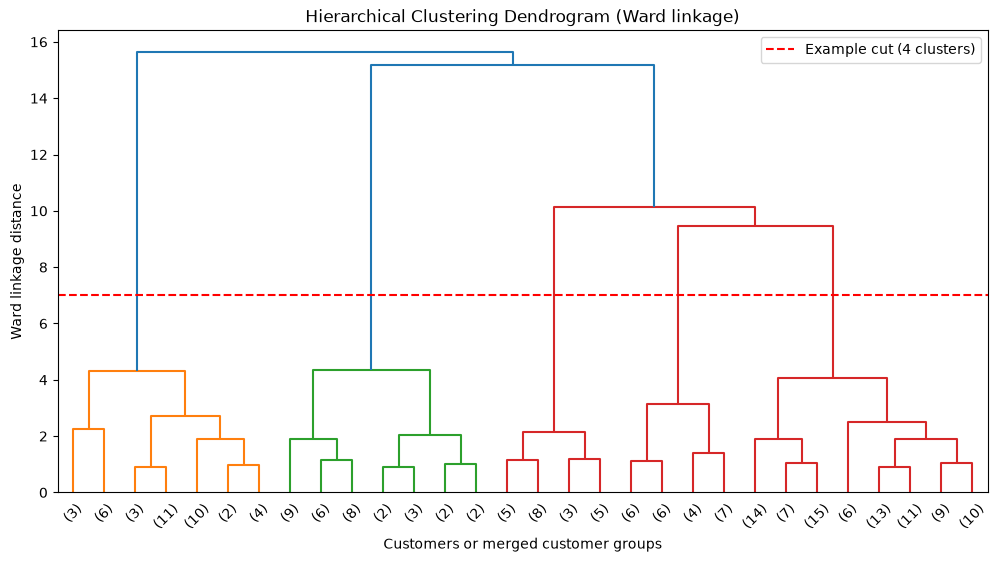

In [10]:
shopping_linkage = linkage(X_shopping, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(shopping_linkage, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.axhline(y=7, color='red', linestyle='--', label='Example cut (4 clusters)')
plt.xlabel('Customers or merged customer groups')
plt.ylabel('Ward linkage distance')
plt.title('Hierarchical Clustering Dendrogram (Ward linkage)')
plt.legend()
plt.show()

Here the Ward dendrogram shows a huge gap between distance such as 4.4 and 9.5. If we try to cut the tree like around at 7 we will get four clusters and it really seems like a good pick for hierarchical clustering and the Elbow Method suggests 5 clusters for the K-Means. So the result varies as the both methods groups the data in a different way.

#### 8. Do clustering using Hierarchical Clustering

In [11]:
hierarchical_shopping = AgglomerativeClustering(n_clusters=4, metric='euclidean', linkage='ward')
shopping_hierarchical_labels = hierarchical_shopping.fit_predict(X_shopping)
print('Hierarchical cluster sizes:', pd.Series(shopping_hierarchical_labels).value_counts().sort_index().to_dict())

Hierarchical cluster sizes: {0: 108, 1: 39, 2: 32, 3: 21}


#### 9. Plot scatter plot and color code in clustered groups

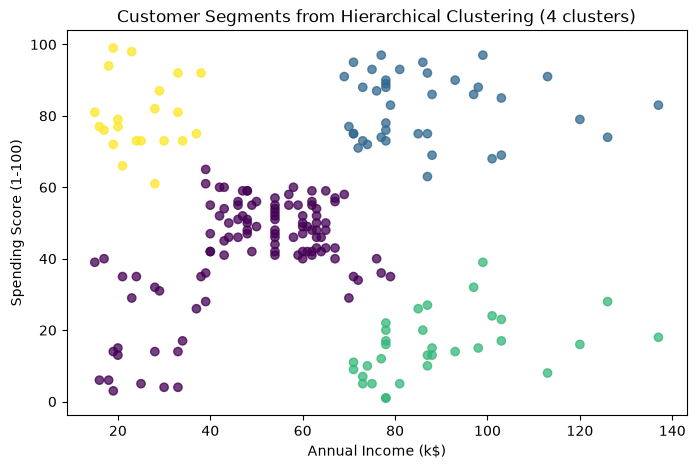

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'],
            c=shopping_hierarchical_labels, cmap='viridis', alpha=0.75)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer Segments from Hierarchical Clustering (4 clusters)')
plt.show()

####  10. Do KMeans and DBSCAN clustering on this data

In [13]:
from sklearn.datasets import make_moons
# moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000, noise=0.05, random_state=42)

Text(0.5, 1.0, 'Half Moons')

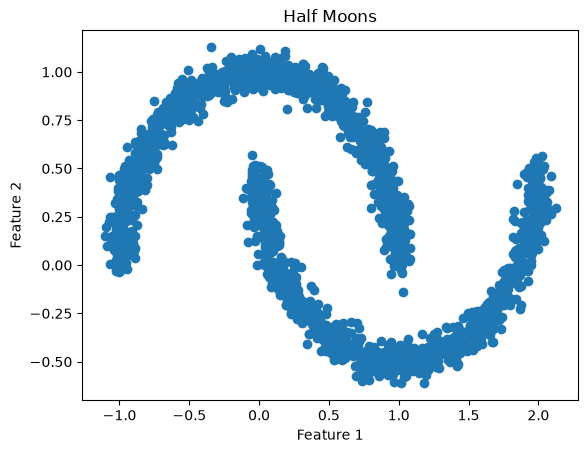

In [14]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [15]:
kmeans_moons = KMeans(n_clusters=2, random_state=42, n_init=10)
moons_kmeans_labels = kmeans_moons.fit_predict(moons_X)

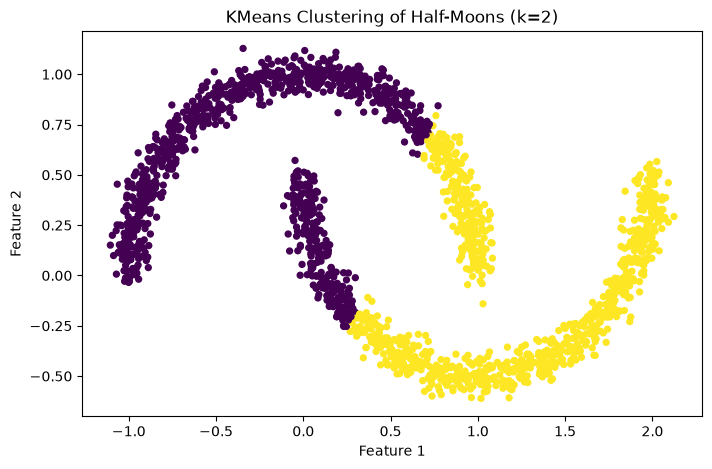

In [16]:
plt.figure(figsize=(8, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=moons_kmeans_labels, cmap='viridis', s=18)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('KMeans Clustering of Half-Moons (k=2)')
plt.show()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

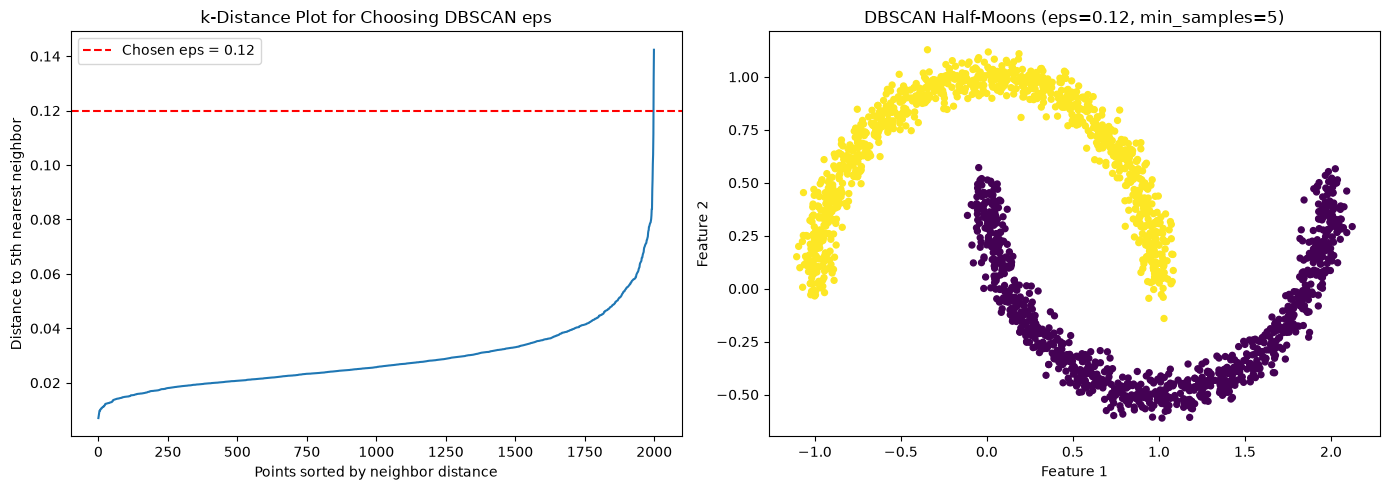

DBSCAN cluster sizes (including noise label -1): {0: 1000, 1: 1000}


In [17]:
min_samples = 5
neighbor_distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(moons_X).kneighbors(moons_X)
k_distances = np.sort(neighbor_distances[:, -1])
dbscan_eps = 0.12
dbscan_moons = DBSCAN(eps=dbscan_eps, min_samples=min_samples)
moons_dbscan_labels = dbscan_moons.fit_predict(moons_X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_distances)
axes[0].axhline(dbscan_eps, color='red', linestyle='--', label=f'Chosen eps = {dbscan_eps}')
axes[0].set_xlabel('Points sorted by neighbor distance')
axes[0].set_ylabel(f'Distance to {min_samples}th nearest neighbor')
axes[0].set_title('k-Distance Plot for Choosing DBSCAN eps')
axes[0].legend()
axes[1].scatter(moons_X[:, 0], moons_X[:, 1], c=moons_dbscan_labels, cmap='viridis', s=18)
axes[1].set_xlabel('Feature 1')
axes[1].set_ylabel('Feature 2')
axes[1].set_title(f'DBSCAN Half-Moons (eps={dbscan_eps}, min_samples={min_samples})')
plt.tight_layout()
plt.show()
print('DBSCAN cluster sizes (including noise label -1):',
      pd.Series(moons_dbscan_labels).value_counts().sort_index().to_dict())

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

KMeans divides the half-moons into two groups, but its centroid-based boundaries are roughly linear and cut across the curved shapes. DBSCAN uses local density instead; with `eps=0.12` and `min_samples=5`, the k-distance plot supports the neighborhood scale and the result recovers the two curved moons (the generated data has modest noise). DBSCAN is therefore preferable for this non-convex dataset. Its result depends on choosing a suitable density scale, while KMeans requires the number of clusters in advance.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [18]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [19]:
print('Shape:', penguins.shape)
display(penguins.dtypes.to_frame('dtype'))
display(penguins.describe(include='all').T)

Shape: (344, 5)


,dtype
culmen_length_mm,float64
culmen_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,str


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
culmen_length_mm,342.0,NaN,NaN,NaN,43.92193,5.459584,32.1,39.225,44.45,48.5,59.6
culmen_depth_mm,342.0,NaN,NaN,NaN,17.15117,1.974793,13.1,15.6,17.3,18.7,21.5
flipper_length_mm,342.0,NaN,NaN,NaN,214.01462,260.558057,-132.0,190.0,197.0,213.75,5000.0
body_mass_g,342.0,NaN,NaN,NaN,4201.754386,801.954536,2700.0,3550.0,4050.0,4750.0,6300.0
sex,335,3,MALE,169,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### Based on dataframe describe, in own words explain any abnormal characteristics 

The Dataset has:

- 344 rows
- four numeric measurements
- and one categorical sex label


The numeric columns each have:

- 342 non-missing values

while sex column has 335. I also noticed some incorrect values in the flipper length column that includes a negative and unusual high value of about 5000mm. These appears to be data errors and should be checked and corrected or removed before analysing the data. 

#### 14. Explore corrupted data

In [20]:
# find missing values. print entries with missing values, provide shape
missing_rows = penguins[penguins.isna().any(axis=1)]
print('Rows containing at least one missing value:', missing_rows.shape)
display(missing_rows)

Rows containing at least one missing value: (9, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [21]:
# Examine sex column
print(penguins['sex'].value_counts(dropna=False))
print('Distinct non-missing sex values:', sorted(penguins['sex'].dropna().unique()))

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64
Distinct non-missing sex values: ['.', 'FEMALE', 'MALE']


In [22]:
# find any unusual values. Print anomal rows
invalid_sex = ~penguins['sex'].isin(['MALE', 'FEMALE']) & penguins['sex'].notna()
invalid_flipper = penguins['flipper_length_mm'].notna() & ~penguins['flipper_length_mm'].between(150, 250)
anomalous_rows = penguins[invalid_sex | invalid_flipper]
print('Rows with invalid labels or implausible flipper length:', anomalous_rows.shape)
display(anomalous_rows)

Rows with invalid labels or implausible flipper length: (3, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE
336,44.5,15.7,217.0,4875.0,.


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [23]:
# Keep complete, plausible measurements for PCA; retain unlabeled rows separately for later prediction.
penguin_numeric_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
valid_measurements = (
    penguins[penguin_numeric_cols].notna().all(axis=1)
    & penguins['flipper_length_mm'].between(150, 250)
)
penguins_clean = penguins.loc[
    valid_measurements & penguins['sex'].isin(['MALE', 'FEMALE'])
].copy()
penguins_unlabeled = penguins.loc[
    valid_measurements & ~penguins['sex'].isin(['MALE', 'FEMALE'])
].copy()
print('Clean labeled data shape:', penguins_clean.shape)
print('Valid rows with unknown sex to predict:', penguins_unlabeled.shape)
display(penguins_clean.head())

Clean labeled data shape: (332, 5)
Valid rows with unknown sex to predict: (8, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE


In [24]:
# scale numerical columns. assign to a variable X_penguins
penguin_scaler = StandardScaler()
X_penguins = penguin_scaler.fit_transform(penguins_clean[penguin_numeric_cols])
print('Scaled feature matrix shape:', X_penguins.shape)

Scaled feature matrix shape: (332, 4)


In [25]:
# assign categorical column to a variable y_penguins
y_penguins = penguins_clean['sex'].copy()
print(y_penguins.value_counts())

sex
MALE      167
FEMALE    165
Name: count, dtype: int64


#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

Rows with missing values cannot be used for PCA, so they are excluded. here the two incorrect flipper length values such as (-132 and 5000mm) are also removed because they are clearly errors. Rows with valid measurements but missing or incorrect sex labels are kept seperately for the later prediction but These rows are not used for PCA or for classifier training.This will help keeping the analysis reliable and also avoids using made up values.To take in account, removing these rows will result in loss of data and will have an impact on the result if there is a pattern in missing values.

#### 16. Perform PCA with 2 components. Plot the results 

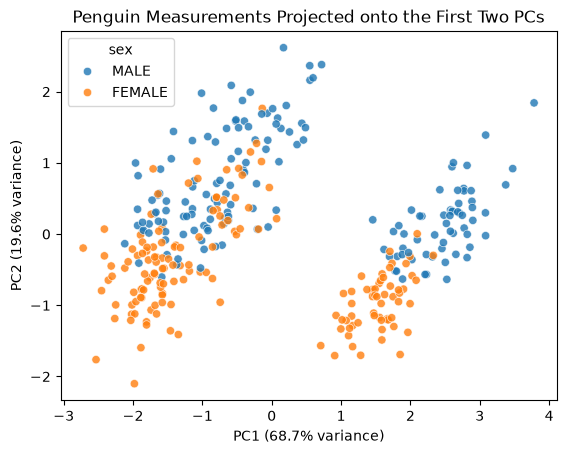

In [26]:
pca_2 = PCA(n_components=2)
X_penguins_pca = pca_2.fit_transform(X_penguins)
pca_plot = pd.DataFrame(X_penguins_pca, columns=['PC1', 'PC2'], index=penguins_clean.index)
pca_plot['sex'] = y_penguins
sns.scatterplot(data=pca_plot, x='PC1', y='PC2', hue='sex', alpha=0.8)
plt.xlabel(f"PC1 ({pca_2.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca_2.explained_variance_ratio_[1]:.1%} variance)")
plt.title('Penguin Measurements Projected onto the First Two PCs')
plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

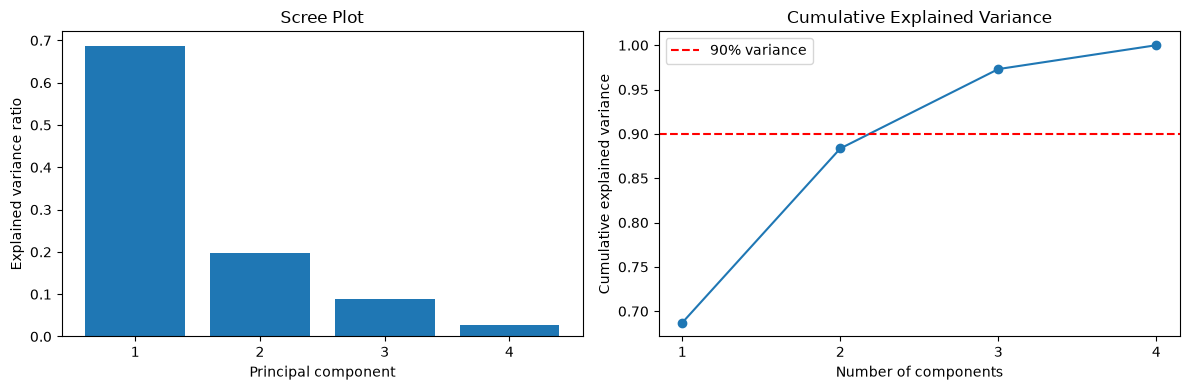

Cumulative explained variance: [0.687 0.884 0.973 1.   ]


In [27]:
pca_full = PCA().fit(X_penguins)
explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)
components = np.arange(1, len(explained_variance) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(components, explained_variance)
axes[0].set_xlabel('Principal component')
axes[0].set_ylabel('Explained variance ratio')
axes[0].set_title('Scree Plot')
axes[0].set_xticks(components)
axes[1].plot(components, cumulative_variance, marker='o')
axes[1].axhline(0.90, color='red', linestyle='--', label='90% variance')
axes[1].set_xlabel('Number of components')
axes[1].set_ylabel('Cumulative explained variance')
axes[1].set_title('Cumulative Explained Variance')
axes[1].set_xticks(components)
axes[1].legend()
plt.tight_layout()
plt.show()
print('Cumulative explained variance:', np.round(cumulative_variance, 3))

#### 18. Calculate (show in numbers) and display component loadings

In [28]:
# Component loadings (how much each original feature contributes to each PC)
component_names = [f'PC{i}' for i in range(1, len(pca_full.components_) + 1)]
pca_loadings = pd.DataFrame(
    pca_full.components_.T * np.sqrt(pca_full.explained_variance_),
    index=penguin_numeric_cols,
    columns=component_names,
)
display(pca_loadings.round(3))

,PC1,PC2,PC3,PC4
culmen_length_mm,0.752,0.537,0.382,-0.049
culmen_depth_mm,-0.662,0.704,-0.259,0.053
flipper_length_mm,0.958,0.003,-0.139,0.257
body_mass_g,0.914,0.064,-0.356,-0.191


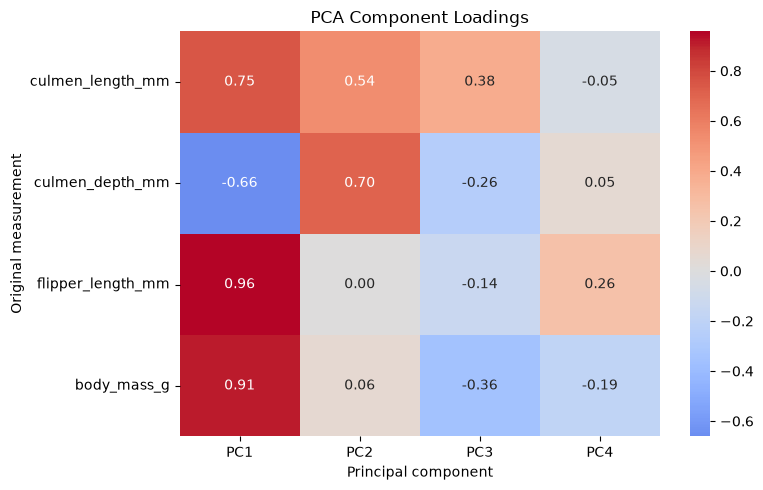

In [29]:
# show heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(pca_loadings, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.xlabel('Principal component')
plt.ylabel('Original measurement')
plt.title('PCA Component Loadings')
plt.tight_layout()
plt.show()

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [30]:
# Evaluate on a held-out stratified test set; the task specifically uses the 2-component PCA representation.
X_train, X_test, y_train, y_test = train_test_split(
    X_penguins_pca, y_penguins, test_size=0.25, random_state=42, stratify=y_penguins
)
penguin_classifier = LogisticRegression(max_iter=1000, random_state=42)
penguin_classifier.fit(X_train, y_train)
y_pred = penguin_classifier.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.3f}')
print(classification_report(y_test, y_pred))
display(pd.DataFrame(
    confusion_matrix(y_test, y_pred, labels=['FEMALE', 'MALE']),
    index=['Actual FEMALE', 'Actual MALE'],
    columns=['Predicted FEMALE', 'Predicted MALE'],
))

Accuracy: 0.855
              precision    recall  f1-score   support

      FEMALE       0.89      0.80      0.85        41
        MALE       0.83      0.90      0.86        42

    accuracy                           0.86        83
   macro avg       0.86      0.85      0.85        83
weighted avg       0.86      0.86      0.86        83



,Predicted FEMALE,Predicted MALE
Actual FEMALE,33,8
Actual MALE,4,38


#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [31]:
# 1. take entries from original data with sex unknown, scale numerical columns
X_unlabeled_scaled = penguin_scaler.transform(penguins_unlabeled[penguin_numeric_cols])
print('Unknown-sex rows with valid measurements:', len(penguins_unlabeled))

Unknown-sex rows with valid measurements: 8


In [32]:
# 2. apply the same PCA transformation to the new data
X_unlabeled_pca = pca_2.transform(X_unlabeled_scaled)
print('Transformed unknown-sex feature shape:', X_unlabeled_pca.shape)

Transformed unknown-sex feature shape: (8, 2)


In [33]:
# 3. Train the model on all valid labeled observations
X_train_all = X_penguins_pca
y_train_all = y_penguins
penguin_classifier_all = LogisticRegression(max_iter=1000, random_state=42)
penguin_classifier_all.fit(X_train_all, y_train_all)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [34]:
# 4. Make predictions on the new data. Display the features and predicted values
unknown_sex_predictions = penguin_classifier_all.predict(X_unlabeled_pca)
penguins_predicted = penguins_unlabeled[penguin_numeric_cols].copy()
penguins_predicted['predicted_sex'] = unknown_sex_predictions
display(penguins_predicted)
print('Predicted sex counts:', pd.Series(unknown_sex_predictions).value_counts().to_dict())

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,predicted_sex
8,34.1,18.1,193.0,3475.0,FEMALE
10,37.8,17.1,186.0,3300.0,FEMALE
11,37.8,17.3,180.0,3700.0,FEMALE
47,37.5,18.9,179.0,2975.0,FEMALE
246,44.5,14.3,216.0,4100.0,FEMALE
286,46.2,14.4,214.0,4650.0,FEMALE
324,47.3,13.8,216.0,4725.0,FEMALE
336,44.5,15.7,217.0,4875.0,FEMALE


Predicted sex counts: {'FEMALE': 8}
